# Paso 7 — Extensión experimental: discretización de las variables

**Condición que se modifica:** la forma en que el modelo ve las variables. En lugar de valores continuos (originales o derivadas), cada variable se reemplaza por indicadores de rango (*k* rangos por variable). Todo lo demás se mantiene igual: los datos simulados, las particiones aleatorias 80/20 (mismas semillas que el Paso 5), los cuatro clasificadores y sus hiperparámetros.

**Motivación.** El trabajo de grado estudia un esquema de *scoring* en el que el modelo recibe rangos atestados en lugar de valores exactos (pruebas de conocimiento cero). La pregunta es cuánto desempeño se pierde cuando la información de entrada se reduce a rangos.

**Hipótesis previas** (formuladas antes de ver los resultados):
1. El desempeño disminuye al reducir el número de rangos *k*; con *k* = 2 la caída es la mayor.
2. Con *k* moderado (5 a 10) el desempeño se mantiene cerca del obtenido con variables derivadas.

**Comparación:** variables originales y derivadas (Paso 5) frente a variables discretizadas con *k* = 2, 3, 5 y 10.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from features import FeatureBuilder
from evaluate import correr_extension

TARGET = "SeriousDlqin2yrs"
(RAIZ / "results").mkdir(exist_ok=True); (RAIZ / "figures").mkdir(exist_ok=True)

## 7.1 Configuración
`N_RUNS` es el número de corridas por valor de *k*; deben ser como máximo las corridas ya disponibles en el Paso 5 (`results/paso5_resultados_por_corrida.csv`), porque la comparación usa las mismas particiones. `MUESTRA` permite usar una submuestra en pruebas rápidas (`None` usa todos los registros).

In [2]:
N_RUNS = 3
KS = [2, 3, 5, 10]
MUESTRA = None

df = pd.read_csv(RAIZ / "data" / "datos_simulados.csv")
if MUESTRA:
    df = df.sample(MUESTRA, random_state=0)
paso5 = pd.read_csv(RAIZ / "results" / "paso5_resultados_por_corrida.csv")
print("corridas disponibles en el Paso 5:", paso5["run"].nunique(), "| corridas de la extensión:", N_RUNS)
assert N_RUNS <= paso5["run"].nunique(), "El Paso 5 tiene menos corridas que N_RUNS"
df.shape

corridas disponibles en el Paso 5: 3 | corridas de la extensión: 3


(150000, 11)

## 7.2 Cortes de los rangos
Los cortes se calculan solo con el conjunto de entrenamiento: cuantiles para las variables continuas y, en las variables de conteo con mucha masa en el mínimo (por ejemplo, atrasos), los primeros valores distintos (0 | 1 | 2 | ...). Si una variable tiene valores faltantes en entrenamiento, se agrega un rango adicional "NA". Ejemplo con *k* = 5 sobre la partición de la corrida 0:

In [3]:
train0, _ = train_test_split(df, test_size=0.2, random_state=1000)
fb = FeatureBuilder("discretized", n_bins=5).fit(train0)
cortes = pd.DataFrame({
    "variable": list(fb.cortes_.keys()),
    "cortes (limite inferior de cada rango, excepto el primero)": [[round(float(x), 2) for x in q] for q in fb.cortes_.values()],
    "rango NA": [fb.tiene_na_[c] for c in fb.cortes_],
})
cortes.to_csv(RAIZ / "results" / "paso7_cortes_k5.csv", index=False)
print("columnas de entrada por valor de k:", {k: len(FeatureBuilder("discretized", n_bins=k).fit(train0).columnas_) for k in KS})
cortes

columnas de entrada por valor de k: {2: 22, 3: 32, 5: 52, 10: 95}


,variable,"cortes (limite inferior de cada rango, excepto el primero)",rango NA
0,RevolvingUtilizationOfUnsecuredLines,"[0.03, 0.11, 0.22, 0.41]",False
1,age,"[40.0, 48.0, 56.0, 65.0]",False
2,NumberOfTime30-59DaysPastDueNotWorse,"[1.0, 2.0, 3.0, 4.0]",False
3,DebtRatio,"[0.2, 0.38, 0.67, 1.29]",False
4,MonthlyIncome,"[2098.94, 3263.17, 4776.65, 7432.57]",True
5,NumberOfOpenCreditLinesAndLoans,"[6.0, 8.0, 9.0, 11.0]",False
6,NumberOfTimes90DaysLate,"[1.0, 2.0, 3.0, 4.0]",False
7,NumberRealEstateLoansOrLines,"[1.0, 2.0, 3.0, 4.0]",False
8,NumberOfTime60-89DaysPastDueNotWorse,"[1.0, 2.0, 3.0, 4.0]",False
9,NumberOfDependents,"[1.0, 2.0, 3.0, 4.0]",True


## 7.3 Experimento
Se ejecutan los cuatro clasificadores con variables discretizadas para cada *k* y cada corrida. Los resultados se guardan de forma incremental en `results/paso7_resultados_por_corrida.csv`; si la ejecución se interrumpe, se retoma donde quedó.

In [4]:
ext = correr_extension(df, n_runs=N_RUNS, ks=KS, destino=RAIZ / "results" / "paso7_resultados_por_corrida.csv")
ext.shape

run 0 / discretized_k2: LLRE AUC=0.913 F1=0.326, RF AUC=0.900 F1=0.530, LLR AUC=0.915 F1=0.555, CART AUC=0.887 F1=0.582
run 0 / discretized_k3: LLRE AUC=0.916 F1=0.305, RF AUC=0.885 F1=0.578, LLR AUC=0.928 F1=0.581, CART AUC=0.855 F1=0.523
run 0 / discretized_k5: LLRE AUC=0.917 F1=0.132, RF AUC=0.904 F1=0.585, LLR AUC=0.932 F1=0.633, CART AUC=0.851 F1=0.619
run 0 / discretized_k10: LLRE AUC=0.918 F1=0.126, RF AUC=0.916 F1=0.566, LLR AUC=0.934 F1=0.638, CART AUC=0.850 F1=0.611
run 1 / discretized_k2: LLRE AUC=0.906 F1=0.346, RF AUC=0.893 F1=0.532, LLR AUC=0.909 F1=0.541, CART AUC=0.880 F1=0.559
run 1 / discretized_k3: LLRE AUC=0.917 F1=0.189, RF AUC=0.881 F1=0.582, LLR AUC=0.922 F1=0.591, CART AUC=0.851 F1=0.548
run 1 / discretized_k5: LLRE AUC=0.905 F1=0.144, RF AUC=0.900 F1=0.595, LLR AUC=0.928 F1=0.635, CART AUC=0.847 F1=0.601
run 1 / discretized_k10: LLRE AUC=0.919 F1=0.123, RF AUC=0.913 F1=0.574, LLR AUC=0.930 F1=0.639, CART AUC=0.846 F1=0.593
run 2 / discretized_k2: LLRE AUC=0.915

(48, 9)

## 7.4 Comparación con variables originales y derivadas

In [5]:
base = paso5[paso5["run"] < N_RUNS]
todo = pd.concat([base, ext[ext["run"] < N_RUNS]], ignore_index=True)
orden_vars = ["original", "derived"] + [f"discretized_k{k}" for k in KS]
orden_clf = ["LLRE", "RF", "LLR", "CART"]

resumen = (todo.groupby(["clasificador", "variables"])[["auc", "f1"]].agg(["mean", "std"]).round(4))
resumen.columns = [f"{m}_{s}" for m, s in resumen.columns]
resumen.to_csv(RAIZ / "results" / "paso7_resumen.csv")

auc = todo.pivot_table(index="clasificador", columns="variables", values="auc").loc[orden_clf, orden_vars].round(4)
f1 = todo.pivot_table(index="clasificador", columns="variables", values="f1").loc[orden_clf, orden_vars].round(4)
print("AUC medio"); display(auc)
print("F-measure medio"); display(f1)

AUC medio


variables,original,derived,discretized_k2,discretized_k3,discretized_k5,discretized_k10
clasificador,,,,,,
LLRE,0.9179,0.9183,0.9114,0.9179,0.9140,0.9170
RF,0.9251,0.9259,0.8980,0.8853,0.9057,0.9176
LLR,0.7339,0.9349,0.9144,0.9271,0.9318,0.9341
CART,0.8565,0.8948,0.8866,0.8573,0.8535,0.8526


F-measure medio


variables,original,derived,discretized_k2,discretized_k3,discretized_k5,discretized_k10
clasificador,,,,,,
LLRE,0.1537,0.3326,0.3288,0.2340,0.1400,0.1395
RF,0.6377,0.6437,0.5385,0.5892,0.5988,0.5773
LLR,0.1002,0.6462,0.5523,0.5933,0.6422,0.6449
CART,0.6086,0.6531,0.5762,0.5509,0.6163,0.6085


In [6]:
# Variación respecto a las variables derivadas (mismas particiones)
filas = []
for clf in orden_clf:
    for k in KS:
        v = f"discretized_k{k}"
        a_d = auc.loc[clf, "derived"]; f_d = f1.loc[clf, "derived"]
        filas.append({"clasificador": clf, "k": k,
                      "AUC": auc.loc[clf, v], "dif_AUC_vs_derived": round(auc.loc[clf, v] - a_d, 4),
                      "F1": f1.loc[clf, v], "dif_F1_vs_derived": round(f1.loc[clf, v] - f_d, 4)})
variacion = pd.DataFrame(filas)
variacion.to_csv(RAIZ / "results" / "paso7_variacion_vs_derivadas.csv", index=False)
variacion

,clasificador,k,AUC,dif_AUC_vs_derived,F1,dif_F1_vs_derived
0,LLRE,2,0.9114,-0.0069,0.3288,-0.0038
1,LLRE,3,0.9179,-0.0004,0.2340,-0.0986
2,LLRE,5,0.9140,-0.0043,0.1400,-0.1926
3,LLRE,10,0.9170,-0.0013,0.1395,-0.1931
4,RF,2,0.8980,-0.0279,0.5385,-0.1052
5,RF,3,0.8853,-0.0406,0.5892,-0.0545
6,RF,5,0.9057,-0.0202,0.5988,-0.0449
7,RF,10,0.9176,-0.0083,0.5773,-0.0664
8,LLR,2,0.9144,-0.0205,0.5523,-0.0939
9,LLR,3,0.9271,-0.0078,0.5933,-0.0529


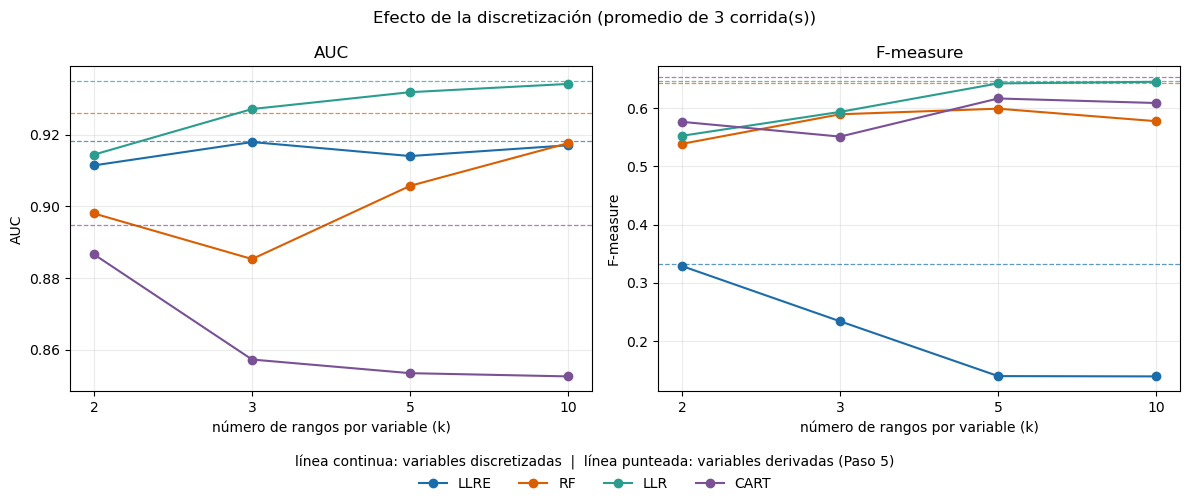

In [7]:
colores = {"LLRE": "#1b6ca8", "RF": "#d95f02", "LLR": "#2a9d8f", "CART": "#7a5195"}
pos = np.arange(len(KS))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, tabla, tit in zip(axes, [auc, f1], ["AUC", "F-measure"]):
    for clf in orden_clf:
        y = [tabla.loc[clf, f"discretized_k{k}"] for k in KS]
        ax.plot(pos, y, marker="o", color=colores[clf], label=clf)
        ax.axhline(tabla.loc[clf, "derived"], color=colores[clf], ls="--", lw=0.9, alpha=0.7)
    ax.set_xticks(pos); ax.set_xticklabels(KS)
    ax.set_xlabel("número de rangos por variable (k)"); ax.set_ylabel(tit); ax.set_title(tit)
    ax.grid(alpha=0.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           title="línea continua: variables discretizadas  |  línea punteada: variables derivadas (Paso 5)")
fig.suptitle(f"Efecto de la discretización (promedio de {N_RUNS} corrida(s))")
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(RAIZ / "figures" / "paso7_discretizacion.png", dpi=130)

## 7.5 Lectura de resultados
Contraste con las hipótesis previas (la interpretación completa está en la sección 5 del notebook principal, `00_analisis_principal.ipynb`):
1. **El desempeño cae al reducir *k*:** se cumple para LLR (AUC 0,934 con *k* = 10 y 0,914 con *k* = 2). No se cumple para RF (la mayor caída es con *k* = 3), CART (empeora al aumentar *k*) ni LLRE (cambios dentro del rango entre corridas).
2. **Con *k* de 5 a 10 el desempeño se mantiene cerca del de las variables derivadas:** se cumple en AUC para LLR y LLRE, y para RF con *k* = 10; no se cumple para CART. En F-measure solo se cumple para LLR.
3. Con 3 corridas, las diferencias menores a 0,01 de AUC no son interpretables.